# 03 — Results: which model is best?

All numbers come from `results/<model>_seed<seed>/` (6 models × seeds 42, 43, 44, trained on one Tesla T4 with identical
settings). The tables and figures are produced by `pneumonia/compare.py` — the same code as
`python scripts/compare_results.py`.

**How to read the numbers.** The primary metric is the **test ROC-AUC**: it measures how well a model separates sick from
healthy children regardless of where the decision threshold is put, and it barely changes between seeds. Accuracy,
recall, specificity, precision and F1 use the fixed threshold 0.5; they depend strongly on where each training run
happens to place its probabilities and vary much more between seeds. Tuning the threshold on the validation set is left
as future work (team decision, see `docs/Plan.md`).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd() if (Path.cwd() / "pneumonia").is_dir() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from IPython.display import Image, Markdown, display

from pneumonia.compare import build_report, collect_runs, summary_markdown

RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
summary = build_report(RESULTS_DIR, FIGURES_DIR)
runs = collect_runs(RESULTS_DIR)
print(f"{len(runs)} runs, {runs['model'].nunique()} models, seeds {sorted(runs['seed'].unique())}")

C:\Users\uid\Documents\VGTU\NeuralNetworks\Course project\pneumonia_image_classification\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


18 runs, 6 models, seeds [np.int64(42), np.int64(43), np.int64(44)]


## 1. Comparison table (test set, mean ± std over 3 seeds)

In [2]:
display(Markdown(summary_markdown(summary)))

| Model | Params (M) | Seeds | ROC-AUC | Accuracy | Recall (sensitivity) | Specificity | Precision | F1 | Train (min) | ms / image |
|---|---|---|---|---|---|---|---|---|---|---|
| Baseline CNN | 0.4 | 3 | 0.935 ± 0.008 | 0.810 ± 0.125 | 0.979 ± 0.019 | 0.530 ± 0.364 | 0.791 ± 0.121 | 0.871 ± 0.071 | 3.3 ± 0.6 | 1.0 ± 0.1 |
| VGG16 | 134.3 | 3 | 0.978 ± 0.008 | 0.914 ± 0.017 | 0.980 ± 0.020 | 0.803 ± 0.060 | 0.893 ± 0.027 | 0.935 ± 0.012 | 10.5 ± 3.2 | 9.7 ± 0.1 |
| ResNet50 | 23.5 | 3 | 0.978 ± 0.001 | 0.904 ± 0.048 | 0.985 ± 0.009 | 0.768 ± 0.142 | 0.880 ± 0.063 | 0.929 ± 0.032 | 5.3 ± 1.9 | 8.4 ± 0.1 |
| DenseNet121 | 7.0 | 3 | 0.978 ± 0.002 | 0.900 ± 0.027 | 0.991 ± 0.001 | 0.746 ± 0.070 | 0.868 ± 0.031 | 0.925 ± 0.019 | 6.3 ± 1.3 | 24.5 ± 0.7 |
| EfficientNet-B0 | 4.0 | 3 | 0.971 ± 0.002 | 0.884 ± 0.006 | 0.994 ± 0.006 | 0.701 ± 0.026 | 0.847 ± 0.011 | 0.915 ± 0.004 | 5.5 ± 1.2 | 13.1 ± 0.2 |
| MobileNetV3-L | 4.2 | 3 | 0.975 ± 0.004 | 0.905 ± 0.009 | 0.983 ± 0.012 | 0.775 ± 0.039 | 0.880 ± 0.017 | 0.928 ± 0.006 | 3.3 ± 1.0 | 10.3 ± 0.7 |


## 2. Metrics per model

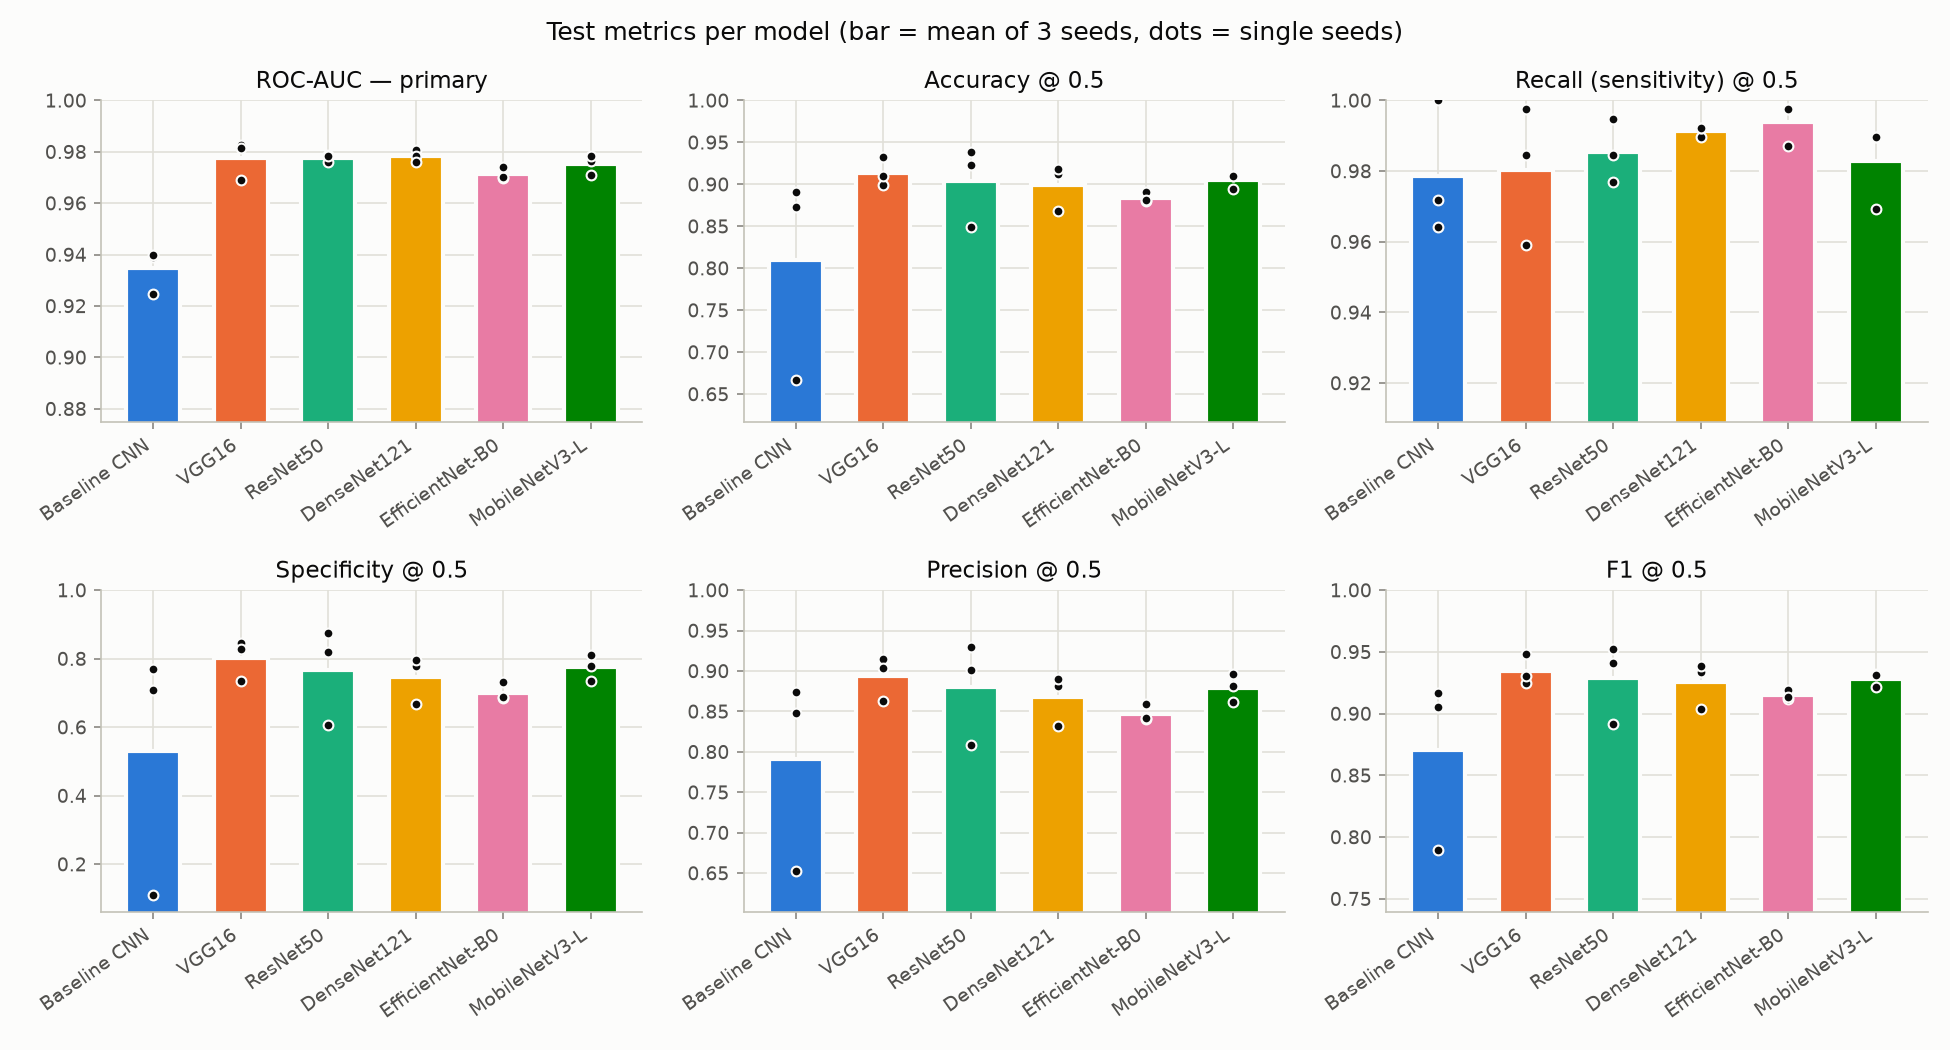

In [3]:
Image(FIGURES_DIR / 'comparison_metrics.png')

- All five ImageNet-pretrained models beat the from-scratch baseline clearly on ROC-AUC (≈0.97–0.98 vs 0.935).
- Among the pretrained models the differences in ROC-AUC (0.971–0.978) are about as large as the seed-to-seed spread —
  VGG16, ResNet50 and DenseNet121 are effectively tied.
- Recall is high for every model (≥ 0.98): almost no sick child is missed. The weak spot is **specificity** — at the
  0.5 threshold many healthy children are called sick, and this number jumps between seeds (baseline 0.11–0.77).

## 3. ROC curves

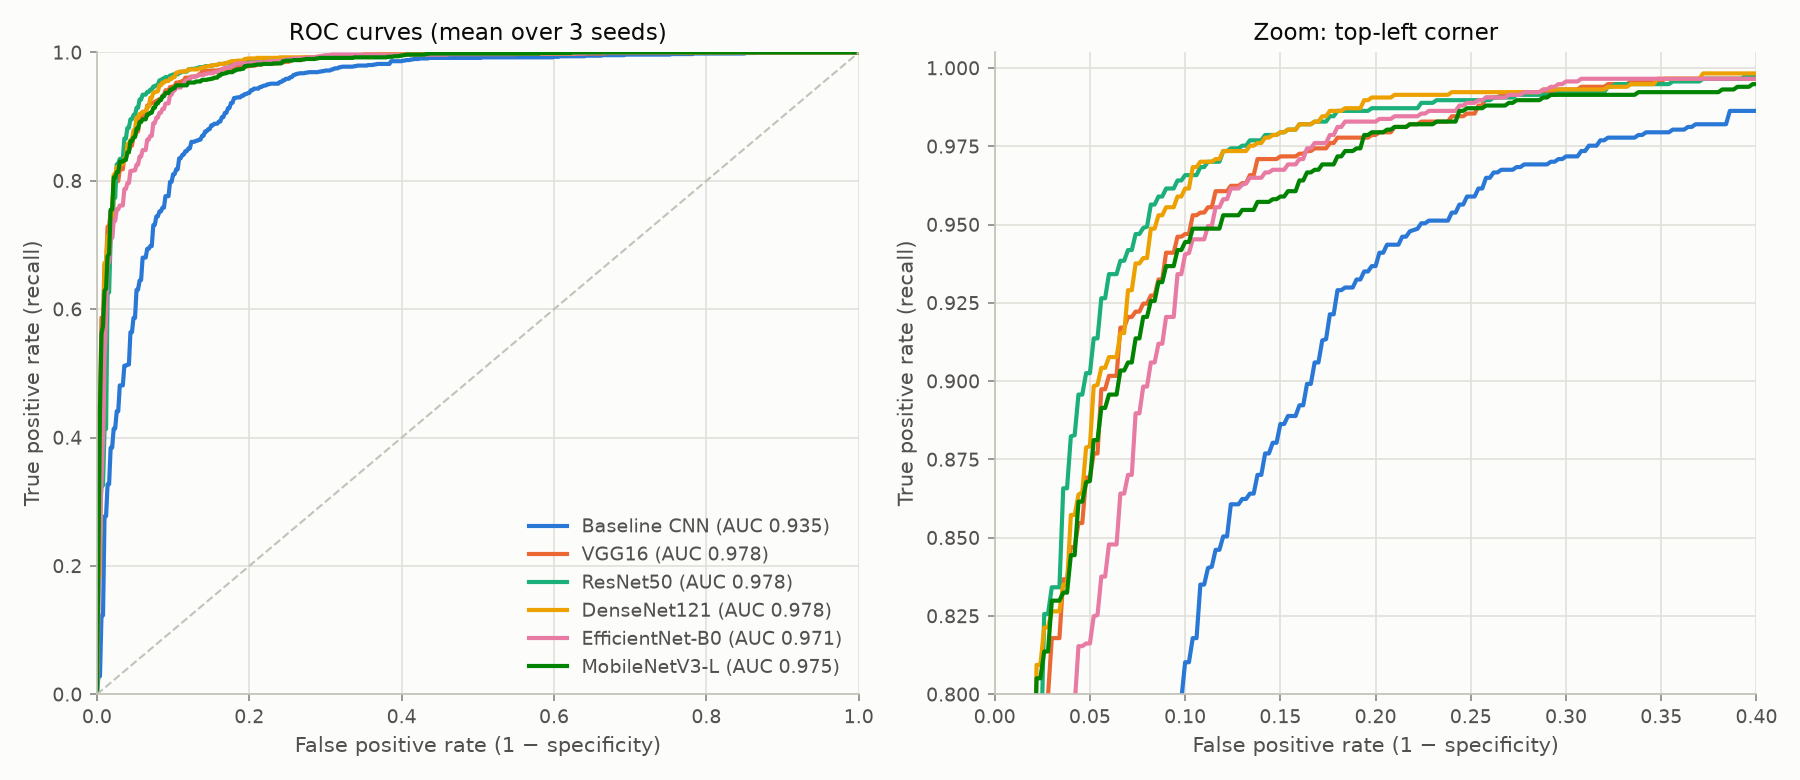

In [4]:
Image(FIGURES_DIR / 'comparison_roc.png')

The curves of the pretrained models lie almost on top of each other; the baseline is visibly lower. Every model could
reach a much better specificity at a small cost in recall by moving the threshold — that is what the curve shows.

## 4. Training curves

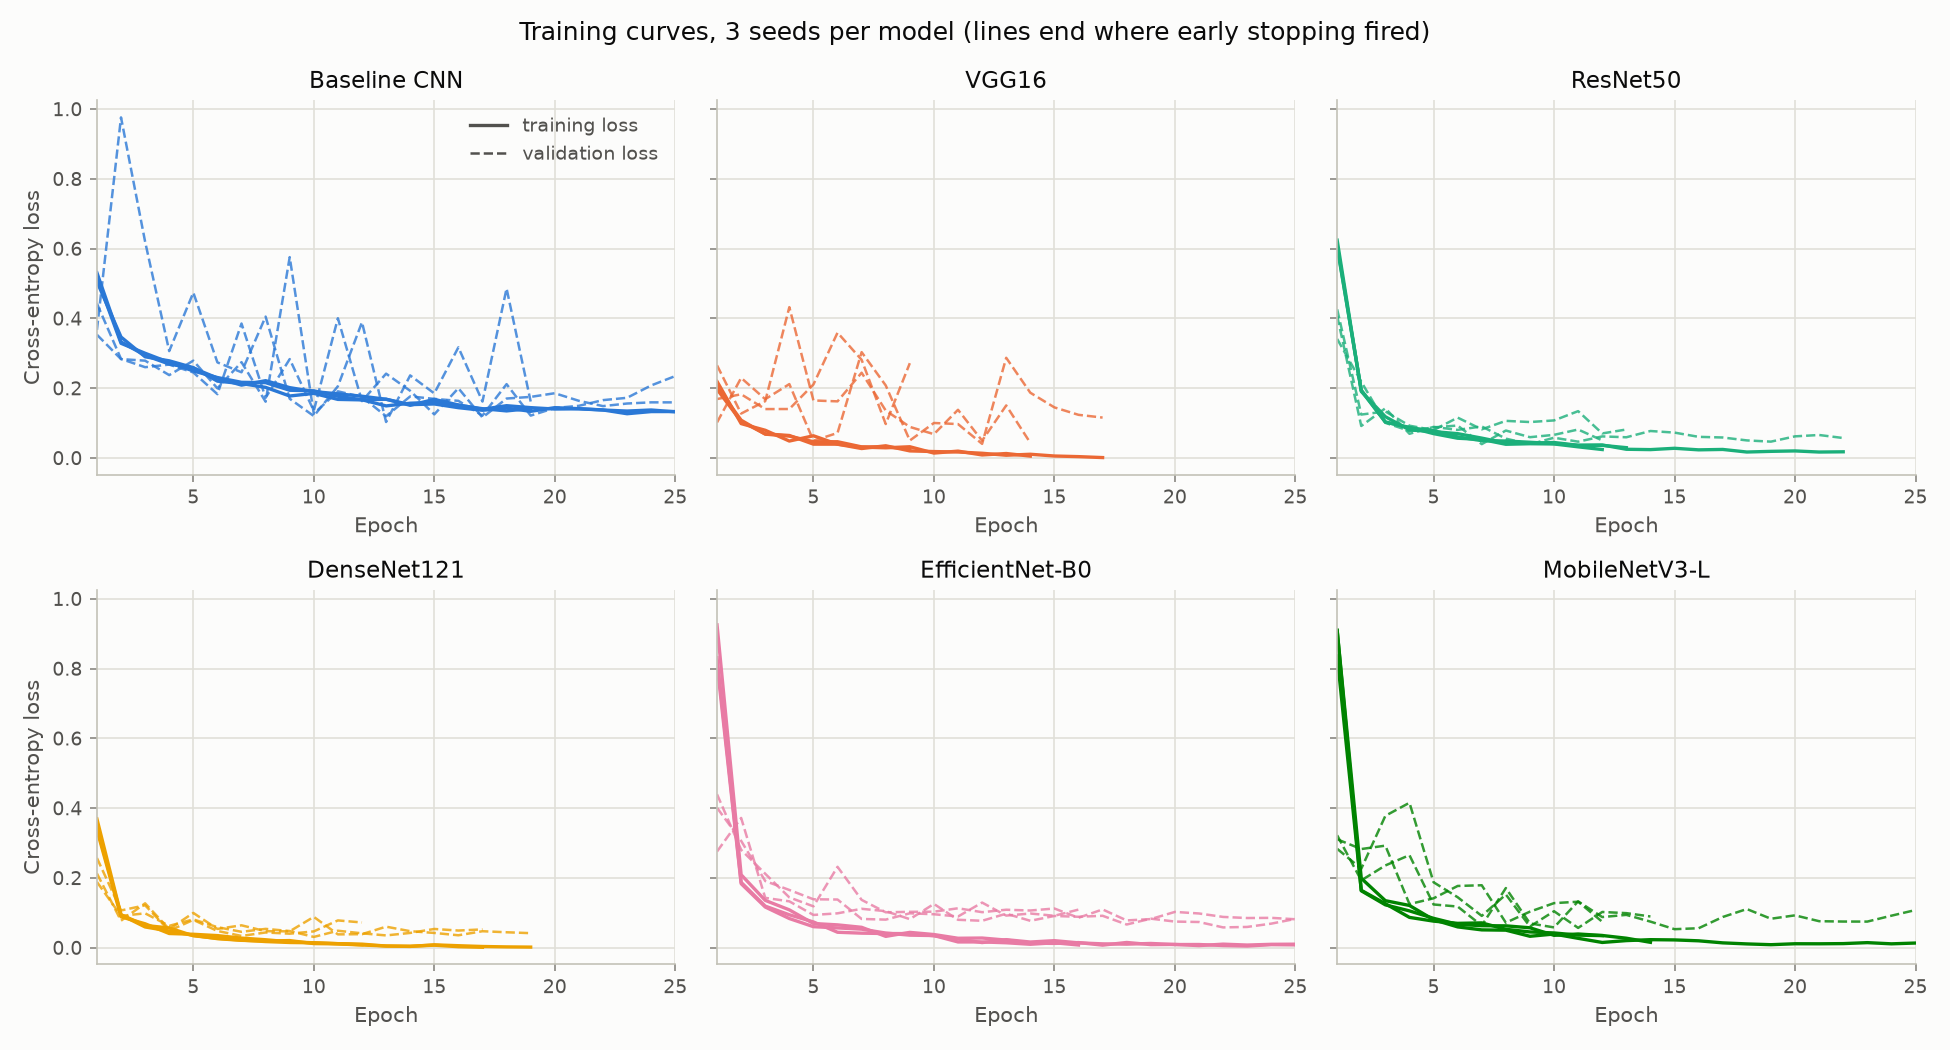

In [5]:
Image(FIGURES_DIR / 'comparison_training_curves.png')

Pretrained models reach their best validation score within a few epochs and then over-fit (training loss → 0).
The validation loss of the baseline and of VGG16 jumps a lot between epochs, although the validation ROC-AUC stays
smooth: the ranking is stable, the probability scale is not.

## 5. Confusion matrices

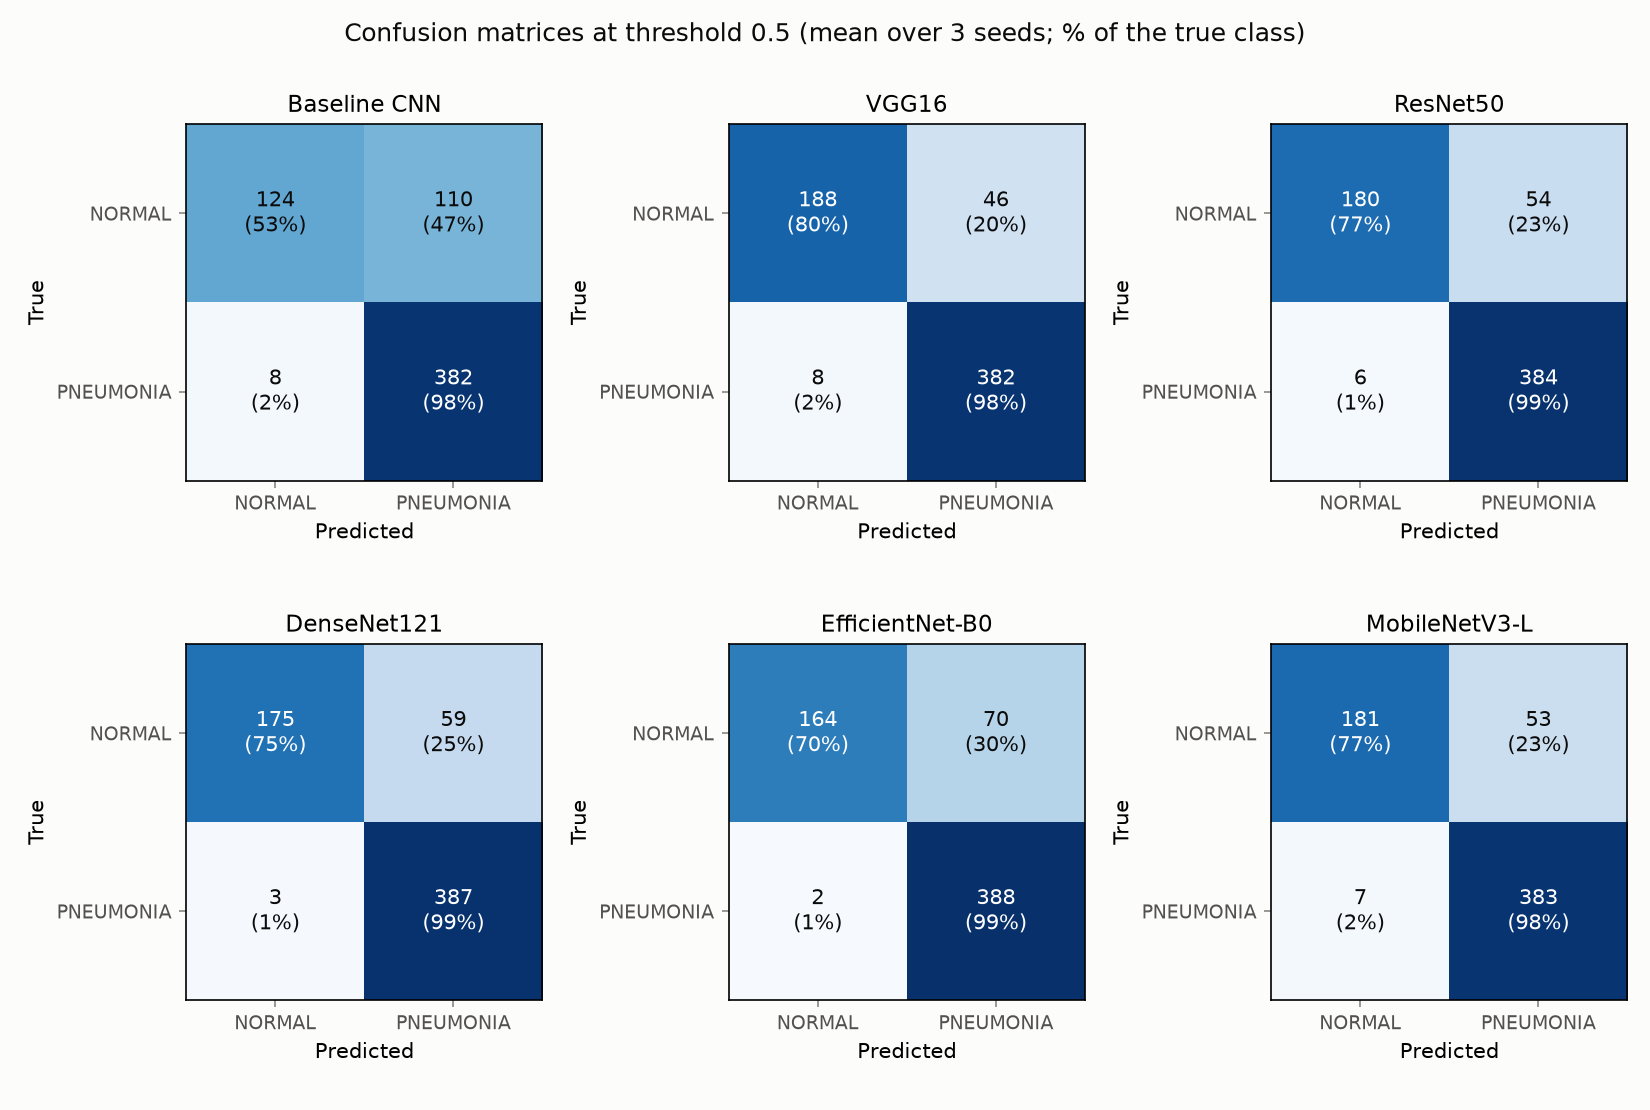

In [6]:
Image(FIGURES_DIR / 'comparison_confusion_matrices.png')

## 6. Quality vs speed and size

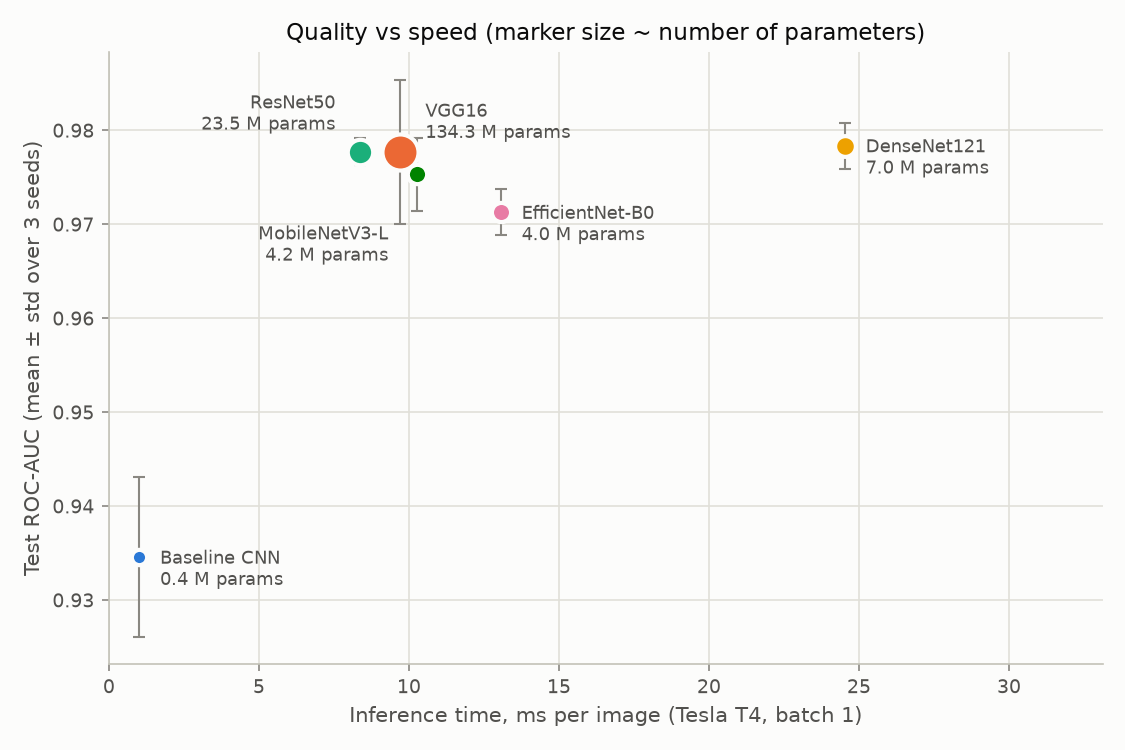

In [7]:
Image(FIGURES_DIR / 'comparison_efficiency.png')

- **MobileNetV3-Large** is the best trade-off: ROC-AUC close to the top, the shortest training of the pretrained models
  and ~10 ms per image with only 4.2 M parameters.
- **VGG16** has the best threshold-0.5 metrics on average but is 32× larger than MobileNetV3 and trains 3× longer.
- **DenseNet121** is the slowest at inference (~25 ms) despite having only 7 M parameters — parameter count is not a good
  proxy for speed.

Grad-CAM pictures of every run (fixed images + that run's most confident mistakes) are in `results/<run>/gradcam.jpg`.

## 7. Where do the models look? (Grad-CAM)

Grad-CAM colours the parts of an X-ray that pushed a model towards its prediction (red = strong influence). Every run
saved heat maps for the same 8 test images (4 NORMAL, 4 PNEUMONIA), so the models can be compared side by side.

In [8]:
from pneumonia.compare import build_gradcam_report

DATA_DIR = REPO_ROOT / "data" / "raw" / "chest_xray"   # needed for the X-ray backgrounds of the image grid
border = build_gradcam_report(RESULTS_DIR, FIGURES_DIR, DATA_DIR if DATA_DIR.is_dir() else None, seed=42)
border.round(3)

,model,border_share_mean,border_share_std,empty_maps
0,baseline_cnn,0.360,0.008,0
1,vgg16,0.420,0.105,6
2,resnet50,0.136,0.030,0
3,densenet121,0.317,0.009,0
4,efficientnet_b0,0.286,0.044,0
5,mobilenetv3_large,0.391,0.046,0


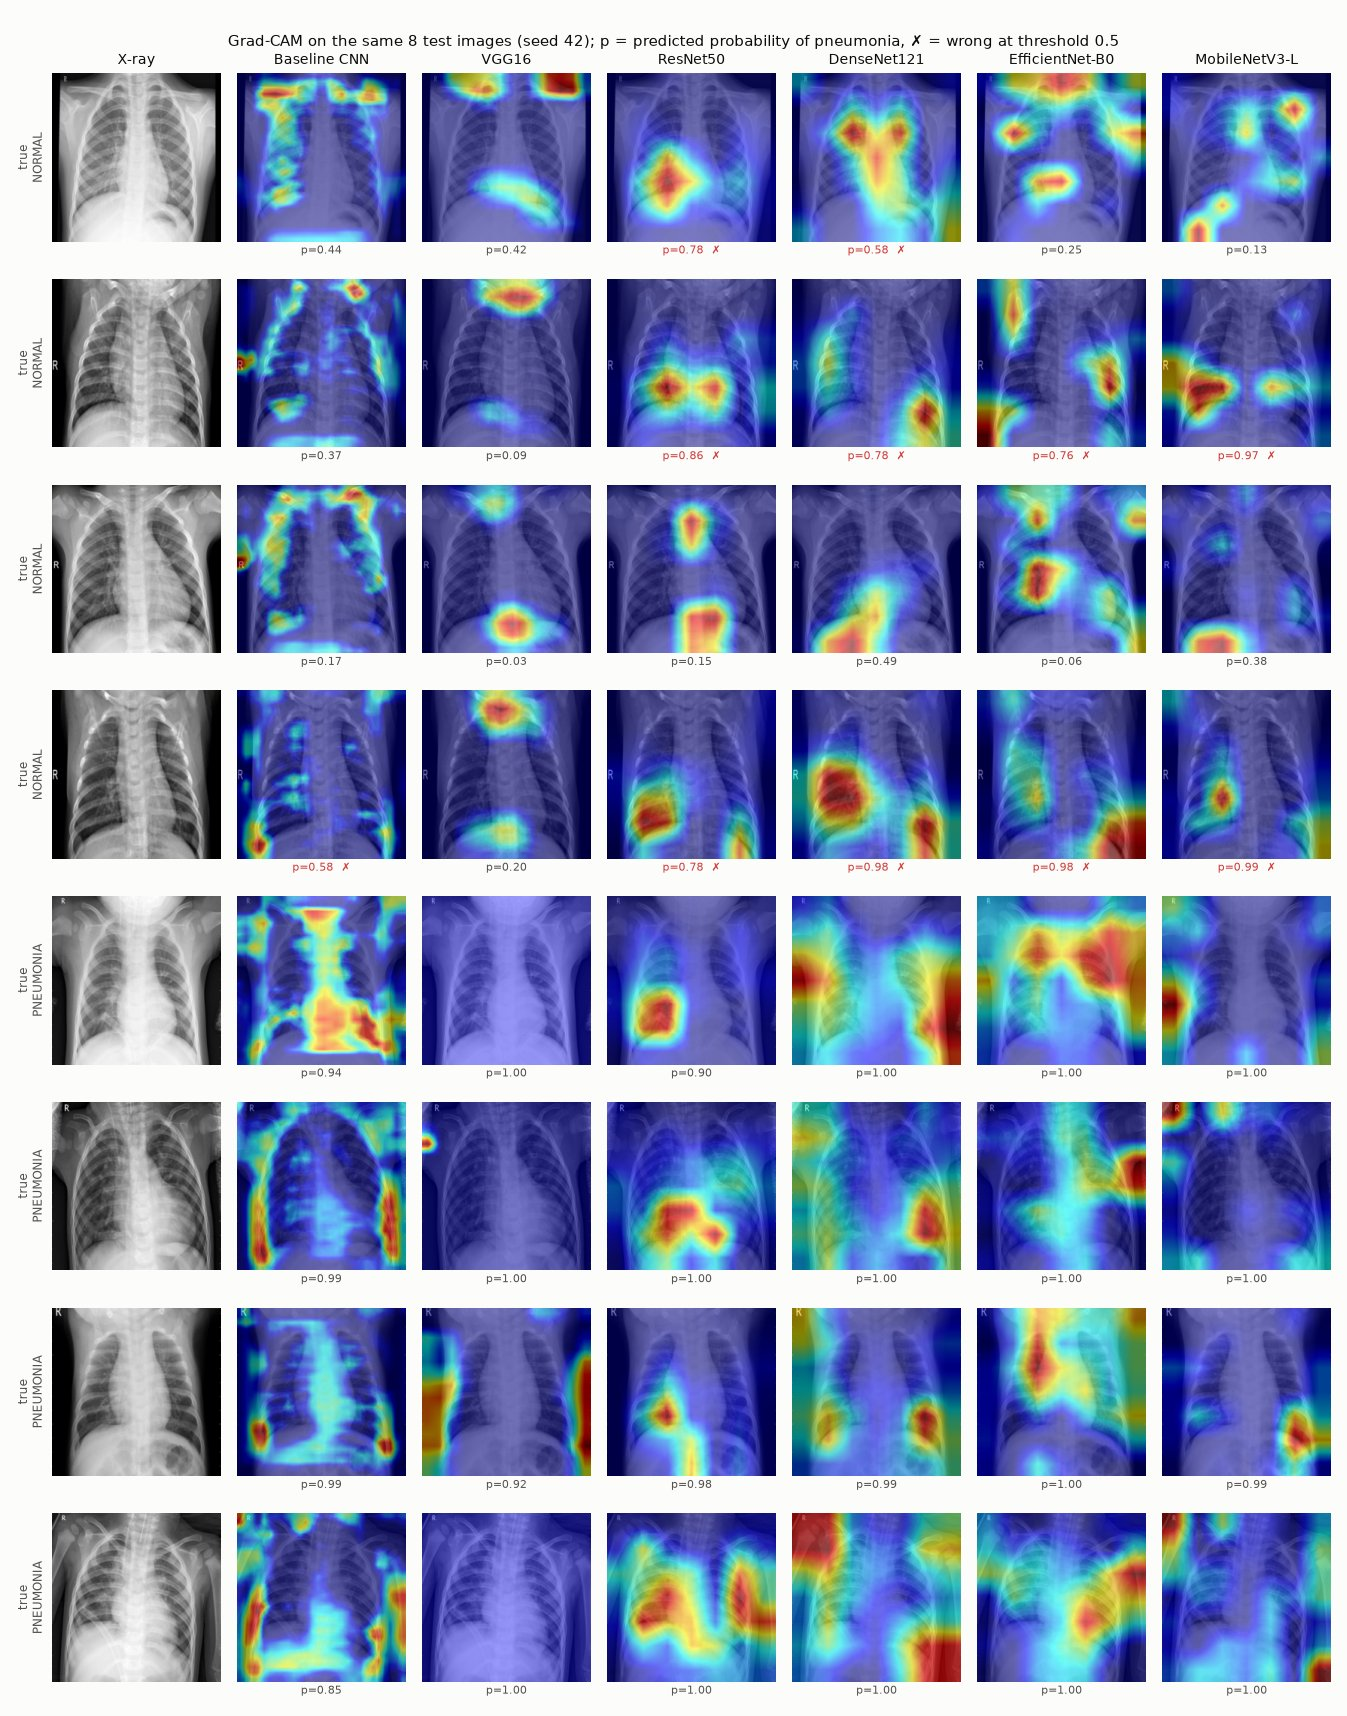

In [9]:
Image(FIGURES_DIR / 'gradcam_comparison_seed42.jpg')

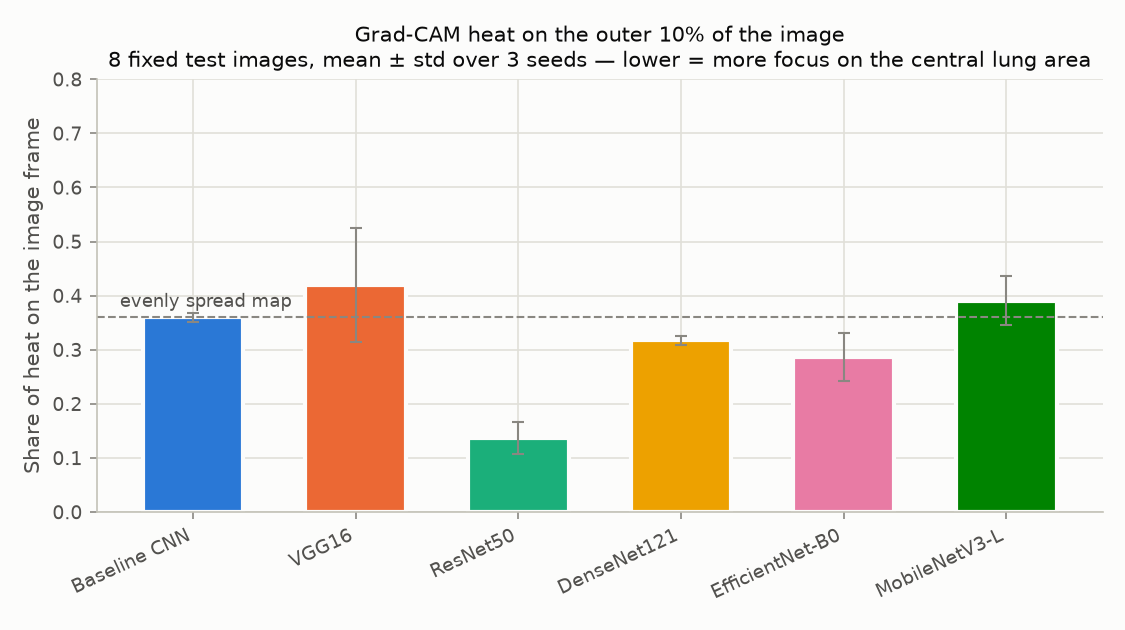

In [10]:
Image(FIGURES_DIR / 'gradcam_border_share.png')

**A simple shortcut check.** The second chart measures how much of each heat map falls on the outer 10 % frame of the
image — where the "R" side marker, shoulders, neck and image edges are, not the lungs. A map spread evenly over the
image would put 36 % there (dashed line).

- **ResNet50** keeps its attention inside the chest (~14 % on the frame, every seed) — in the grid its maps sit on
  the lung fields, even for its mistakes on healthy children.
- **VGG16, MobileNetV3 and the baseline** put as much or more heat on the frame than an evenly spread map
  (36–42 %): image corners, the "R" marker, shoulders and neck often light up. VGG16 also produces **empty** maps for
  several images it is very sure about (6 of 24) — its decision cannot be explained there at all.
- **DenseNet121 and EfficientNet-B0** are in between (29–32 %).

Similar ROC-AUC therefore does not mean similar reasoning: the models with the same test score look at very different
parts of the image, and some of them may partly rely on shortcuts that would not transfer to X-rays from another
hospital. Caveats: only 8 images per run, Grad-CAM shows the evidence for the *predicted* class, and the "frame" is a
crude proxy for "not lungs" (no lung masks are available).